# LandscapeSHAP demo: curvature detection, exact point-level Shapley values

This notebook applies the LandscapeSHAP pipeline to the point-cloud sampling scheme from
Bubenik et al., "Persistent Homology Detects Curvature": point clouds sampled uniformly from
a geodesic ball of fixed radius in a space of constant curvature `c`, for `c` swept over
`[-2, 2]`. The task is regression, not classification: predict the (continuous) curvature
value from a persistence landscape built from the cloud's **1-dimensional Vietoris-Rips
persistent homology**.

**Training on averaged landscapes, matching Bubenik et al.'s own setup.** Rather than
training on all 10,100 individual per-cloud landscapes, this notebook averages the 100
landscapes at each curvature value into a single row, giving **101** training rows -- one per
curvature -- matching the paper's reported design (which also found a near-perfect diagonal
fit via 1D PCA on these averaged landscapes, replicated here as an independent sanity check
right after model training). Averaging over 100 repeats is a real noise reduction (variance
of a mean shrinks like `1/100`), not just a row-count reduction, which is presumably why the
paper's own fit came out so clean despite the small number of resulting rows. Because a linear
model's score is linear in its input, the Shapley value of a point in one of the 100 diagrams
underlying a given curvature's average pulls back *exactly*: it's `1/100` times that point's
own closed-form Shapley value computed as if its diagram alone were the input (see Section 6).

**Why Vietoris-Rips, not alpha complex.** The dynamical-system LandscapeSHAP notebook used
the alpha complex, which needs literal Euclidean point coordinates and a Delaunay
triangulation. Points sampled from a positively- or negatively-curved ball do not live in
flat Euclidean space -- only their pairwise *geodesic* distances are geometrically meaningful.
The Vietoris-Rips complex is built purely from a distance matrix, curvature-agnostic by
construction, which is why it's the right (and the requested) choice here.

**A real scale risk, addressed with the right tool.** The exact requested scale is 101
curvature values (step 0.04) x 100 repeats x 1000 points/cloud = **10,100** Rips H1
computations at N=1000 points each. GUDHI's general-purpose RipsComplex/SimplexTree is not the
best-suited tool for this: `ripser` is a purpose-built algorithm for exactly this task (low-
dimensional persistence from a distance matrix) and is well known to be substantially faster
here. Section 2/3 below use `ripser` for the bulk of the sweep, where only birth/death
*values* are needed (no cycle reconstruction), and keep GUDHI only for the 3 example clouds in
Section 6, which need to know which specific edge caused each class -- ripser's plain output
doesn't expose that (getting it would need `do_cocycles=True` and post-processing a cohomology
representative, a more involved object than "here's the birth edge, BFS from there"). A small
timed pilot still runs first and prints a measured extrapolated runtime estimate *before* the
full sweep runs, since neither `ripser` nor `gudhi` could be benchmarked while writing this (no
network access in the authoring sandbox to install either) -- treat that pilot number as the
actual source of truth, not anything claimed here.

**The Bubenik et al. sampling code has been bug-fixed and its distance functions rewritten
for speed.** Reviewing the pasted implementation surfaced three correctness issues, fixed in
Section 1 below and marked with `# FIX:` comments: a shape mismatch and an off-by-one loop
bound in the large-radius spherical fallback path (`sample_sph2`, would crash if triggered),
and a likely-unintended bias in the multiplicative noise term (`np.random.normal(1)` draws
from a Normal(mean=1, ...) rather than a standard normal -- inert here since `noise=0.0`, but
fixed anyway). Separately, and more importantly for this notebook's scale: `hyp_distance`,
`euc_distance`, and `sph_distance` originally computed the N x N distance matrix with a
double **Python** `for` loop over all pairs -- at N=1000 that's ~500,000 Python-level
iterations *per cloud*, and with 10,100 clouds requested here that alone (before GUDHI is even
involved) could plausibly take hours. They've been rewritten with numpy broadcasting (same
formulas, `# VECTORIZED` comments mark the change), which should be at least two orders of
magnitude faster at this N.

This notebook:

1. Defines the (bug-fixed) curvature-ball sampling code.
2. Defines Vietoris-Rips H1 two ways: `ripser` (fast, values only -- used for the bulk of the
   sweep) and GUDHI (slower, but exposes the birth edge -- used only for the 3 examples).
3. Runs a timed pilot, then generates the full dataset: for each of 101 curvature values,
   samples 100 point clouds of 1000 points each, turns each into a landscape feature row
   (`K=25` layers, `M=100` grid points), and **averages the 100 rows into one** -- giving a
   `(101, 2500)` feature matrix. H1 diagrams and raw point clouds are **not** kept in memory
   beyond that (keeping all 10,100 distance matrices would need on the order of 80 GB), except
   for one representative diagram per example curvature (-2, 0, 2), kept for Section 6.
4. Trains a **linear SVM regressor** (`LinearSVR`) on the 101 averaged rows to predict
   curvature, then runs a **1D PCA sanity check** on the same averaged rows as an independent
   check that the pipeline reproduces the paper's reported near-perfect diagonal fit.
5. Computes **exact, closed-form Shapley values** (Theorem 1 in the write-up), adapted here
   for a single continuous regression output rather than a one-vs-rest multiclass score.
6. Plots one representative diagram per example curvature (-2, 0, 2), colored by its
   **pullback-scaled** Shapley value (`1/100` of its own-diagram closed-form value -- its
   actual contribution to the trained model's use of that curvature's averaged landscape),
   with the top-5 |Shapley| points' representative H1 cycles drawn and colored the same way.
   Note: points sampled from a positive-curvature ball are inherently one ambient dimension
   higher than flat/negative-curvature points (an artifact of how the sphere embeds, not a
   bug), so the curvature=2 example is plotted in 3D while the other two are plotted in 2D.

**Other design choices made where the request was ambiguous** (documented again at the end):
ball radius = 1.0 and intrinsic dimension = 2 (so points are 2D for `c<=0`, 3D for `c>0`);
`noise=0.0`; and, since a Rips complex on 1000 points is far denser than the alpha complex's
Delaunay edges, the cycle plots below do **not** draw the full background graph (it would be
an unreadable, oversized mess at this scale) -- only the point cloud and the reconstructed
loop itself.


In [1]:
!pip install -q gudhi ripser

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 67.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 843.4/843.4 kB 36.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.6/48.6 kB 2.0 MB/s eta 0:00:00


In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import gudhi
from ripser import ripser
from collections import deque
from sklearn.svm import LinearSVR
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

RNG_SEED = 42
# The Bubenik et al. sampling code below uses the legacy global `np.random` state (calls like
# np.random.uniform(), np.random.randn()) rather than a Generator instance, so we seed that
# global state directly for reproducibility -- everything else in the notebook (train_test_split,
# etc.) uses `random_state=RNG_SEED` via sklearn's own mechanism, no conflict.
np.random.seed(RNG_SEED)


## 1. Sample point clouds from balls of constant curvature (Bubenik et al., bug-fixed)

Unchanged from the reviewed version except for three correctness fixes, each marked `# FIX:`
below (`sample_sph2`'s array shape and off-by-one loop bound; the multiplicative-noise bias
in the three `*_distance` functions, inert here since `noise=0.0`), plus one performance
rewrite: `hyp_distance`/`euc_distance`/`sph_distance` are vectorized with numpy broadcasting
instead of a double Python `for` loop, marked `# VECTORIZED` -- essential at this notebook's
scale (10,100 clouds of 1000 points each), not just a nicety.


In [3]:
# integrate sinh^(n)(ax) from 0 to r
def integrate_sinh(n, r, a):
    if n == 0:
        return r
    elif n == 1:
        return (np.cosh(a * r) - 1) / a
    else:
        return (np.sinh(a * r) ** (n - 1)) * np.cosh(a * r) / (a * n) - (n - 1) / n * integrate_sinh(n - 2, r, a)


def integrate_sin(n, r, a):
    if n == 0:
        return r
    elif n == 1:
        return (1 - np.cos(a * r)) / a
    else:
        return -(np.sin(a * r) ** (n - 1)) * np.cos(a * r) / (a * n) + (n - 1) / n * integrate_sin(n - 2, r=r, a=a)


def hyp_radial_density(r, d, curvature, radius_to_sample_from):
    k = np.sqrt(-curvature)
    hyp_r = (np.sinh(k * r)) ** (d - 1) / integrate_sinh(d - 1, radius_to_sample_from, k)
    return hyp_r


def euc_radial_density(r, d, radius_to_sample_from):
    return d * (r ** (d - 1)) / radius_to_sample_from ** d


def sph_radial_density(r, d, curvature, radius_to_sample_from):
    k = np.sqrt(curvature)
    sph_r = (np.sin(k * r)) ** (d - 1) / integrate_sin(d - 1, radius_to_sample_from, k)
    return sph_r


def rejection_sampling(dens, maxval, numofpts):
    max_val = dens(maxval)
    iter = 1
    rands = []
    while iter <= numofpts:
        x = np.random.uniform() * maxval
        val = dens(x)
        u = np.random.uniform()
        if u * max_val < val:
            rands.append(x)
            iter += 1
    return rands


def sample_hyp_rad(d, curvature, radius_of_ball, numofpts):
    rands = rejection_sampling(lambda x: hyp_radial_density(x, d, curvature, radius_of_ball), radius_of_ball, numofpts)
    k = 1 / np.sqrt(-curvature)
    f = lambda x: k * np.tanh(x / (2.0 * k))
    euc_rands = map(f, rands)
    euc_rands = np.fromiter(euc_rands, dtype=float)
    return euc_rands


def sample_sph_rad(d, curvature, radius_of_ball, numofpts):
    rands = rejection_sampling(lambda x: sph_radial_density(x, d, curvature, radius_of_ball), radius_of_ball, numofpts)
    return np.array(rands)


def sample_euc_rad(d, radius_of_ball, numofpts):
    rands = rejection_sampling(lambda x: euc_radial_density(x, d, radius_of_ball), radius_of_ball, numofpts)
    return np.array(rands)


def normalize(v):
    norm = np.linalg.norm(v)
    if norm == 0:
        return v
    return v / norm


def sample_sphere(d, numofpts):
    vecs = np.random.randn(numofpts, d)
    rands = np.zeros((numofpts, d))
    for i in range(numofpts):
        rands[i, :] = normalize(vecs[i, :])
    return rands


def sample_hyp(d, curvature, radius, numofpts):
    sphere_pts = sample_sphere(d, numofpts)
    radii = sample_hyp_rad(d, curvature, radius, numofpts)
    ball_pts = [radii[i] * sphere_pts[i] for i in range(numofpts)]
    return ball_pts


def sample_sph2(d, curvature, numofpts):
    k = 1 / np.sqrt(curvature)
    rands = np.zeros((numofpts, d + 1))  # FIX: was (numofpts, d) -- points on a d-sphere need d+1 ambient coords
    i = 0
    while i < numofpts:  # FIX: was i <= numofpts (off-by-one, wrote past the array's end)
        vec = np.random.randn(d + 1)
        if vec[d] > 0:
            rands[i, :] = k * normalize(vec)
            i += 1
    return rands


def sample_sph(d, curvature, radius, numofpts):
    k = 1 / np.sqrt(curvature)
    if radius > np.pi * k / 2:
        ball_pts = sample_sph2(d, curvature, numofpts)
    else:
        radii = sample_sph_rad(d, curvature, radius, numofpts)
        angs = radii / k
        other_cords = np.expand_dims(k * np.sin(angs), 1) * sample_sphere(d, numofpts)
        ball_pts = [np.append(other_cords[i, :], (k * np.cos(angs[i]))) for i in range(numofpts)]
    return ball_pts


def sample_hyp_cone(d, curvature, radius, numofpts, cone_size):
    sphere_pts = sample_sph(d - 1, 1, cone_size, numofpts)
    radii = sample_hyp_rad(d, curvature, radius, numofpts)
    cone_pts = [radii[i] * sphere_pts[i] for i in range(numofpts)]
    return cone_pts


def sample_euc(d, radius, numofpts):
    sphere_pts = sample_sphere(d, numofpts)
    radii = sample_euc_rad(d, radius, numofpts)
    ball_pts = [radii[i] * sphere_pts[i] for i in range(numofpts)]
    return ball_pts


def sample_euc_cone(d, radius, numofpts, cone_size):
    sphere_pts = sample_sph(d - 1, 1, cone_size, numofpts)
    radii = sample_euc_rad(d, radius, numofpts)
    cone_pts = [radii[i] * sphere_pts[i] for i in range(numofpts)]
    return cone_pts


def sample_ball(d, curvature, radius, numofpts):
    if curvature < 0:
        ball_pts = sample_hyp(d, curvature, radius, numofpts)
    elif curvature == 0.0:
        ball_pts = sample_euc(d, radius, numofpts)
    elif curvature > 0:
        ball_pts = sample_sph(d, curvature, radius, numofpts)
    return ball_pts


def _symmetric_noise_factor(n, noise):
    """A (n,n) symmetric multiplicative-noise factor: one independent draw per unordered
    pair, mirrored, diagonal fixed at 1 (distances[i,i] is always 0 regardless)."""
    if noise == 0:
        return 1.0
    raw = np.random.normal(size=(n, n))  # FIX: was np.random.normal(1) per pair (biased, mean 1)
    raw = np.triu(raw, 1)
    raw = raw + raw.T
    factor = 1 + noise * raw
    np.fill_diagonal(factor, 1.0)
    return factor


def hyp_distance(pts, curvature, noise):
    # VECTORIZED (numpy broadcasting) -- the original used a double Python for-loop over all
    # N(N-1)/2 pairs, which at N=1000 is ~500,000 Python-level iterations *per cloud*; with
    # 10,100 clouds in this notebook that alone could take hours, independent of GUDHI/H1
    # entirely. Same formula, vectorized: nx_i = 1-|c|*||pt_i||^2, delta_ij as before.
    pts = np.asarray(pts, dtype=float)
    norms2 = np.sum(pts ** 2, axis=1)
    nvals = 1 - np.abs(curvature) * norms2
    diff2 = np.sum((pts[:, None, :] - pts[None, :, :]) ** 2, axis=-1)
    delta = 2 * abs(curvature) * diff2 / (nvals[:, None] * nvals[None, :])
    dist = (1 / np.sqrt(-curvature)) * np.arccosh(1 + delta)
    dist = dist * _symmetric_noise_factor(len(pts), noise)
    np.fill_diagonal(dist, 0.0)
    return dist


def euc_distance(pts, noise):
    # VECTORIZED -- see hyp_distance's comment.
    pts = np.asarray(pts, dtype=float)
    dist = np.linalg.norm(pts[:, None, :] - pts[None, :, :], axis=-1)
    dist = dist * _symmetric_noise_factor(len(pts), noise)
    np.fill_diagonal(dist, 0.0)
    return dist


def sph_distance(pts, curvature, noise):
    # VECTORIZED -- see hyp_distance's comment.
    pts = np.asarray(pts, dtype=float)
    k = 1 / np.sqrt(curvature)
    diff_norm = np.linalg.norm(pts[:, None, :] - pts[None, :, :], axis=-1)
    sum_norm = np.linalg.norm(pts[:, None, :] + pts[None, :, :], axis=-1)
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = np.where(sum_norm > 0, diff_norm / np.where(sum_norm > 0, sum_norm, 1.0), 0.0)
    dist = 2 * k * np.arctan(ratio)
    dist = dist * _symmetric_noise_factor(len(pts), noise)
    np.fill_diagonal(dist, 0.0)
    return dist


def distance_matrix(pts, curvature, noise):
    if curvature < 0:
        return hyp_distance(pts, curvature, noise)
    elif curvature == 0:
        return euc_distance(pts, noise)
    elif curvature > 0:
        return sph_distance(pts, curvature, noise)


## 2. 1-dimensional persistent homology via Vietoris-Rips: two backends

Both are built directly from a distance matrix -- curvature-agnostic, unlike the alpha
complex. Two different implementations are used for two different purposes:

`compute_h1_values_ripser` uses `ripser`, a purpose-built implicit-reduction algorithm for
exactly this workload (low-dimensional persistence from a distance matrix), and is
substantially faster than a general simplicial-complex library at this N. It returns only
birth/death *values* -- enough for the landscape features -- and is used for the bulk of the
10,100-cloud sweep in Section 3.

`compute_h1_rips` uses GUDHI, which is slower in general but whose `persistence_pairs()`
directly exposes *which edge* (2 vertices) caused each H1 class -- needed to reconstruct a
representative cycle by BFS in Section 6. It's used only for the 3 example clouds, where
speed is irrelevant (3 calls total), so no edge-collapse or other acceleration is needed here
-- correctness and simplicity win over speed for those.


In [4]:
def compute_h1_values_ripser(D, max_edge_length):
    """H1 (birth, death) VALUES only (no simplex/cycle info) via ripser -- fast, purpose-
    built for exactly this. Used for the bulk of the dataset, where only landscape features
    (not representative cycles) are needed. Classes still alive at max_edge_length (death =
    infinity) are dropped, matching how compute_h1_rips below only returns finite pairs."""
    result = ripser(D, distance_matrix=True, maxdim=1, thresh=max_edge_length)
    dgm1 = result["dgms"][1]
    return [(float(b), float(d)) for b, d in dgm1 if np.isfinite(d)]


def compute_h1_rips(D, max_edge_length):
    """H1 persistence pairs WITH birth/death simplex info, via GUDHI -- only used for the 3
    example clouds in Section 6, where cycle reconstruction needs the actual birth edge.
    Returns a list of (birth, death, birth_simplex, death_simplex) tuples; birth_simplex /
    death_simplex are lists of vertex indices into the point cloud that produced D. Unlike the
    alpha complex, Rips filtration values ARE the raw distances -- no square root needed."""
    rc = gudhi.RipsComplex(distance_matrix=D, max_edge_length=max_edge_length)
    st = rc.create_simplex_tree(max_dimension=2)  # only 3 calls total, no need to economize
    st.persistence(homology_coeff_field=2, min_persistence=0)
    h1 = []
    for birth_s, death_s in st.persistence_pairs():
        if len(birth_s) == 2 and len(death_s) == 3:
            b = st.filtration(birth_s)
            d = st.filtration(death_s)
            h1.append((b, d, birth_s, death_s))
    return h1


## 3. Generate the dataset: pilot timing, then the full sweep

Unlike the dynamical-system notebook, sampling, H1, and landscape featurization all happen
**inline in one pass** here rather than as three separate passes over a fully materialized
point-cloud list: keeping all 10,100 distance matrices in memory (1000x1000 floats each) would
need roughly 80 GB, so each cloud's distance matrix is discarded immediately after its H1
diagram is extracted. Per curvature value, the 100 individual landscape rows are summed into a
running accumulator and divided by `N_REPEATS` once all 100 are in, giving the single averaged
row that curvature contributes to `X` -- so the final feature matrix is `(101, K*M)`, not
`(10100, K*M)`. The one exception to "nothing is kept": one representative (un-averaged)
diagram per example curvature (-2, 0, 2) is kept in full for Section 6's pullback-scaled plots.

The pilot below uses `ripser` (matching what 10,097 of the 10,100 main-sweep clouds will
actually use -- only the 3 examples use the slower GUDHI path, negligible either way) and a
generous `max_edge_length` (the full triangle-inequality diameter bound, `2 * RADIUS` --
guaranteed not to truncate any real feature) on a handful of clouds, to safely discover the
true death-value range *and* get a realistic per-cloud timing. The full sweep then uses a
tighter, data-derived `max_edge_length`, so it should run at least as fast as the pilot's
(deliberately pessimistic) estimate -- likely faster.


In [5]:
DIM = 2            # intrinsic dimension: points are 2D for c<=0 (flat/hyperbolic), and
                    # (DIM+1)=3D for c>0 (a curvature>0 ball is a cap of a DIM-sphere, which
                    # embeds in DIM+1 ambient coordinates -- inherent to the sampling code)
RADIUS = 1.0        # fixed ball radius across the whole curvature sweep, chosen so it stays
                    # inside the safe (monotonic-density) rejection-sampling regime for every
                    # c in [-2, 2] on the spherical side (radius < pi*k/2 for k=1/sqrt(2)~=0.71
                    # at the sweep's largest c=2), while still being large relative to the
                    # curvature scale k at the extremes so curvature effects are actually felt
N_POINTS = 1000
N_REPEATS = 100
CURVATURES = np.round(np.linspace(-2.0, 2.0, 101), 2)  # step 0.04, matches the request exactly
K = 25
M = 100
NOISE_FRAC = 0.02
EXAMPLE_CURVATURES = [-2.0, 0.0, 2.0]

def landscape(h1, grid, K):
    N = len(h1)
    Mg = len(grid)
    if N == 0:
        return np.zeros((K, Mg))
    b = np.array([p[0] for p in h1])
    d = np.array([p[1] for p in h1])
    tent = np.minimum(np.maximum(0.0, grid[None, :] - b[:, None]),
                       np.maximum(0.0, d[:, None] - grid[None, :]))
    sorted_tent = np.sort(tent, axis=0)[::-1]
    L = np.zeros((K, Mg))
    L[:min(K, N)] = sorted_tent[:min(K, N)]
    return L


In [6]:
# --- Pilot: discover a safe grid range + get a realistic per-cloud timing estimate -------
PILOT_CURVATURES = [-2.0, -1.0, 0.0, 1.0, 2.0]
PILOT_REPEATS = 2
PILOT_MAX_EDGE_LENGTH = 2.0 * RADIUS  # full diameter bound: safe, never truncates a real
                                       # feature, but slower than what the main run will use

pilot_deaths = []
pilot_times = []
for c in PILOT_CURVATURES:
    for _ in range(PILOT_REPEATS):
        t0 = time.time()
        pts = np.array(sample_ball(DIM, c, RADIUS, N_POINTS))
        D = distance_matrix(pts, c, noise=0.0)
        h1 = compute_h1_values_ripser(D, PILOT_MAX_EDGE_LENGTH)
        pilot_times.append(time.time() - t0)
        pilot_deaths.extend([p[1] for p in h1])

pilot_deaths = np.array(pilot_deaths)
if len(pilot_deaths) == 0:
    raise RuntimeError("Pilot found zero H1 features across all pilot clouds -- check "
                        "RADIUS/DIM/N_POINTS before running the full sweep.")

GRID_MAX = float(np.percentile(pilot_deaths, 99) * 1.1)
EPSILON = NOISE_FRAC * GRID_MAX
MAX_EDGE_LENGTH = min(GRID_MAX * 1.2, 2.0 * RADIUS)  # tighter than the pilot's safe bound
grid = np.linspace(0.0, GRID_MAX, M)

avg_time = float(np.mean(pilot_times))
n_total_clouds = len(CURVATURES) * N_REPEATS
print(f"Pilot (ripser): {len(pilot_times)} clouds, avg {avg_time:.2f}s/cloud "
      f"(generous pilot threshold -- production uses a tighter one, should be at least as fast)")
print(f"GRID_MAX={GRID_MAX:.4f}  EPSILON={EPSILON:.5f}  production MAX_EDGE_LENGTH={MAX_EDGE_LENGTH:.4f}")
print(f"Full sweep: {n_total_clouds} clouds. Pessimistic estimate at pilot speed: "
      f"{avg_time * n_total_clouds / 60:.1f} min ({avg_time * n_total_clouds / 3600:.2f} hours).")
print("If that's too large, reduce N_REPEATS and/or coarsen the curvature step before the next cell.")


Pilot (ripser): 10 clouds, avg 1.27s/cloud (generous pilot threshold -- production uses a tighter one, should be at least as fast)
GRID_MAX=0.1851  EPSILON=0.00370  production MAX_EDGE_LENGTH=0.2222
Full sweep: 10100 clouds. Pessimistic estimate at pilot speed: 213.1 min (3.55 hours).
If that's too large, reduce N_REPEATS and/or coarsen the curvature step before the next cell.


In [7]:
# --- Full sweep: accumulate the 100 landscapes per curvature, then average -------------
X_rows, y_curv = [], []
examples = {}  # curvature (rounded) -> dict(points, dist, h1, X_row, curvature, avg_row_idx)

t_start = time.time()
cloud_i = 0
for c in CURVATURES:
    landscape_accum = np.zeros(K * M)
    for rep in range(N_REPEATS):
        pts = np.array(sample_ball(DIM, c, RADIUS, N_POINTS))
        D = distance_matrix(pts, c, noise=0.0)
        is_example = rep == 0 and any(abs(c - ec) < 1e-9 for ec in EXAMPLE_CURVATURES)

        if is_example:
            # Only 3 clouds ever take this path -- GUDHI, so Section 6 has the birth edge
            # needed for cycle reconstruction. Speed doesn't matter here.
            h1_raw = compute_h1_rips(D, MAX_EDGE_LENGTH)
            h1 = [p for p in h1_raw if (p[1] - p[0]) > EPSILON]
        else:
            # The other 10,097 clouds: ripser, values only, fast.
            h1_raw = compute_h1_values_ripser(D, MAX_EDGE_LENGTH)
            h1 = [p for p in h1_raw if (p[1] - p[0]) > EPSILON]

        feat = landscape(h1, grid, K).flatten()
        landscape_accum += feat

        if is_example:
            # This one representative diagram's OWN (un-averaged) landscape/H1 is kept for
            # Section 6's pullback-scaled Shapley plot -- not the average, one diagram.
            examples[round(float(c), 2)] = {"points": pts, "dist": D, "h1": h1,
                                             "X_row": feat, "curvature": float(c)}

        cloud_i += 1
        if cloud_i % 1000 == 0:
            elapsed = time.time() - t_start
            rate = elapsed / cloud_i
            remaining = rate * (n_total_clouds - cloud_i)
            print(f"[{cloud_i}/{n_total_clouds}] elapsed={elapsed/60:.1f}min  "
                  f"est. remaining={remaining/60:.1f}min")

    X_rows.append(landscape_accum / N_REPEATS)
    y_curv.append(c)
    c_key = round(float(c), 2)
    if c_key in examples:
        examples[c_key]["avg_row_idx"] = len(X_rows) - 1

X = np.array(X_rows)
y = np.array(y_curv)
print("Feature matrix (averaged, one row per curvature):", X.shape)
print("Collected example clouds for curvatures:", sorted(examples.keys()))
assert all(ec in examples for ec in EXAMPLE_CURVATURES), \
    "Missing an example curvature -- check EXAMPLE_CURVATURES against CURVATURES."


[1000/10100] elapsed=3.0min  est. remaining=27.5min
[2000/10100] elapsed=6.1min  est. remaining=24.5min
[3000/10100] elapsed=9.1min  est. remaining=21.6min
[4000/10100] elapsed=12.3min  est. remaining=18.7min
[5000/10100] elapsed=15.4min  est. remaining=15.7min
[6000/10100] elapsed=19.2min  est. remaining=13.1min
[7000/10100] elapsed=23.3min  est. remaining=10.3min
[8000/10100] elapsed=27.4min  est. remaining=7.2min
[9000/10100] elapsed=31.5min  est. remaining=3.9min
[10000/10100] elapsed=35.7min  est. remaining=0.4min
Feature matrix (averaged, one row per curvature): (101, 2500)
Collected example clouds for curvatures: [-2.0, 0.0, 2.0]


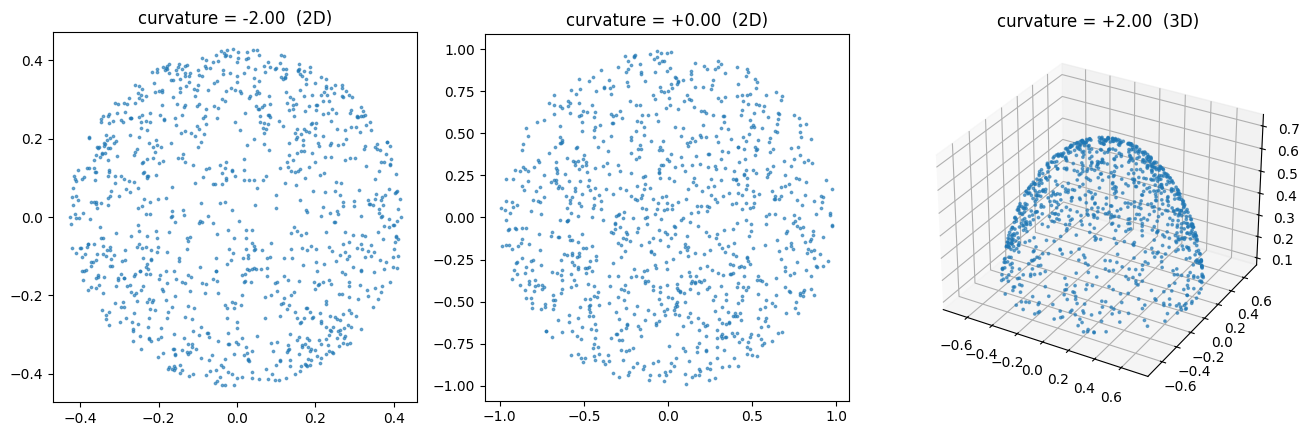

In [8]:
fig = plt.figure(figsize=(13, 4.5))
for col, ec in enumerate(EXAMPLE_CURVATURES):
    pc = examples[ec]["points"]
    proj = "3d" if pc.shape[1] == 3 else None
    ax = fig.add_subplot(1, 3, col + 1, projection=proj)
    if pc.shape[1] == 2:
        ax.scatter(pc[:, 0], pc[:, 1], s=3, alpha=0.6)
        ax.set_aspect("equal")
    else:
        ax.scatter(pc[:, 0], pc[:, 1], pc[:, 2], s=3, alpha=0.6)
    ax.set_title(f"curvature = {ec:+.2f}  ({pc.shape[1]}D)")
plt.tight_layout()
fig.savefig("curvature_examples.svg", format="svg", bbox_inches="tight")
plt.show()


## 4. Train a linear SVM regressor (on the averaged landscapes) + a PCA sanity check

`LinearSVR` instead of `LinearSVC`: the target here is the continuous curvature value, not a
class label, so there's a single output rather than a one-vs-rest score per class. `X` here is
the `(101, K*M)` averaged-landscape matrix from Section 3, not the 10,100-row per-cloud one --
101 rows for a 2500-feature linear regression is a small training set in the usual ML sense
(after a 75/25 split, ~76 train / ~25 test rows), worth being upfront about; it's not a
guess at robustness so much as a direct replication of Bubenik et al.'s own reported design,
and averaging over 100 repeats is a genuine noise reduction (variance of a mean shrinks like
`1/N_REPEATS`) rather than just fewer, noisier rows.

Right after training, a **1D PCA** on the same 101 averaged rows gives an independent sanity
check: the paper reports a near-perfect diagonal fit between the leading principal component
and curvature. If this notebook's PC1-vs-curvature plot looks similarly clean, that's good
evidence the sampling/H1/landscape pipeline is reproducing the same underlying signal the
paper found, before trusting anything built on top of it (the regressor, the Shapley values).


In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RNG_SEED)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

model = LinearSVR(C=1.0, epsilon=0.0, max_iter=20000)
model.fit(X_train_s, y_train)
pred_test = model.predict(X_test_s)
print("Test R^2:", model.score(X_test_s, y_test))
print("Test MAE:", float(np.mean(np.abs(pred_test - y_test))))


Test R^2: 0.9878281278299443
Test MAE: 0.06617967692218255


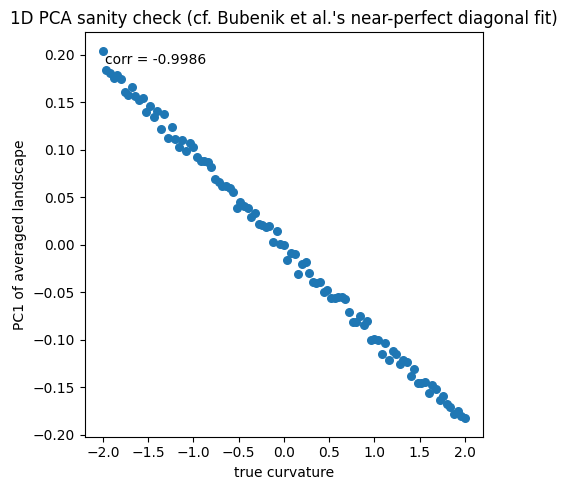

PC1 vs curvature correlation: -0.9985997553820228
Explained variance ratio (PC1): 0.9661844558564813


In [10]:
from sklearn.decomposition import PCA

pca = PCA(n_components=1)
pc1 = pca.fit_transform(X).flatten()  # fit on all 101 rows -- unsupervised sanity check,
                                       # not part of the train/test predictive evaluation

corr = float(np.corrcoef(y, pc1)[0, 1])
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y, pc1, s=30)
ax.set_xlabel("true curvature")
ax.set_ylabel("PC1 of averaged landscape")
ax.set_title("1D PCA sanity check (cf. Bubenik et al.'s near-perfect diagonal fit)")
ax.text(0.05, 0.95, f"corr = {corr:.4f}", transform=ax.transAxes, va="top")
plt.tight_layout()
fig.savefig("curvature_pca_check.svg", format="svg", bbox_inches="tight")
plt.show()

print("PC1 vs curvature correlation:", corr)
print("Explained variance ratio (PC1):", float(pca.explained_variance_ratio_[0]))


## 5. Exact, closed-form point-level Shapley values (LandscapeSHAP)

Same closed-form machinery as the other notebooks (Theorem 1 in the write-up), with
`rescaled_weights` simplified for a regressor: `LinearSVR.coef_` is a single `(n_features,)`
vector (no per-class selection needed, unlike `LinearSVC.coef_`'s `(n_classes, n_features)`).
The order-statistic game itself (`order_stat_suffix` / `column_all_layers_shapley`) is
completely model- and domain-agnostic, unchanged from the other notebooks, including the
fix (clipping `max(r,k+1)` to at most `N+1`) for diagrams with fewer than `K` points -- which
will be common here too, since not every curvature/repeat produces 25+ surviving H1 features.


In [11]:
def order_stat_suffix(values):
    """values: 1D array of raw (non-negative) values for one 'column' game.
    Returns (order, S) with S[j-1] = S_j = sum_{j'=j}^{N} (t_(j')-t_(j'+1))/j'  (1-indexed j),
    and S[N] = 0 appended, so phi for rank r at layer k is S[max(r,k+1)-1]."""
    N = len(values)
    order = np.argsort(-values, kind="stable")
    tsort = values[order]
    tpad = np.append(tsort, 0.0)
    j = np.arange(1, N + 1)
    gaps = tpad[:-1] - tpad[1:]
    terms = gaps / j
    suffix = np.cumsum(terms[::-1])[::-1]
    return order, np.append(suffix, 0.0)

def column_all_layers_shapley(values, K, weights):
    """Exact Shapley contribution of every player (original order), summed over layers
    k=0..K-1 of the SAME column, weighted by `weights[k]`. One sort, O(K) lookups.

    When the column has fewer than k+1 points (N < k+1), the k-th order-statistic game is
    identically zero (the sum defining phi is empty), so max(r,k+1) is clipped to N+1 before
    indexing -- S[N] is exactly that zero sentinel."""
    N = len(values)
    if N == 0:
        return np.zeros(0)
    order, S = order_stat_suffix(values)
    rank_of = np.empty(N, dtype=int)
    rank_of[order] = np.arange(1, N + 1)
    contrib = np.zeros(N)
    for k in range(K):
        idx = np.minimum(np.maximum(rank_of, k + 1), N + 1) - 1
        contrib += weights[k] * S[idx]
    return contrib

def point_shapley(h1, grid, K, w_landscape):
    """w_landscape: (K, M) rescaled weights for the landscape block."""
    N = len(h1)
    if N == 0:
        return np.zeros(0)
    b = np.array([p[0] for p in h1])
    d = np.array([p[1] for p in h1])
    phi = np.zeros(N)
    for m, gm in enumerate(grid):
        tent_m = np.minimum(np.maximum(0.0, gm - b), np.maximum(0.0, d - gm))
        phi += column_all_layers_shapley(tent_m, K, w_landscape[:, m])
    return phi

def rescaled_weights(model, scaler, K, M):
    """w_hat = w / sigma on the RAW (unscaled) feature vector; no per-class selection --
    LinearSVR has a single output."""
    w_full = model.coef_ / scaler.scale_
    return w_full.reshape(K, M), w_full

def pca_weights(pca, K, M):
    """PC1 is itself a linear function of the landscape: pca.transform(x)[0] =
    <components_[0], x - mean_> = <components_[0], x> - const. That's exactly the f(x) =
    <w,x>+b form Theorem 1 needs, with w = components_[0] -- no scaler division here, since
    (unlike the regressor) PCA was fit directly on the raw, unscaled landscape matrix X."""
    w_full = pca.components_[0]
    return w_full.reshape(K, M), w_full


In [12]:
# Self-check: closed form vs brute-force permutation Shapley on small random examples.
import itertools

def brute_force_column_shapley(values, k):
    N = len(values)
    def v(idx_set):
        if len(idx_set) <= k:
            return 0.0
        return sorted((values[i] for i in idx_set), reverse=True)[k]
    phi = np.zeros(N)
    perms = list(itertools.permutations(range(N)))
    for perm in perms:
        coalition, v_prev = [], v([])
        for p in perm:
            coalition.append(p)
            v_cur = v(coalition)
            phi[p] += v_cur - v_prev
            v_prev = v_cur
    return phi / len(perms)

check_rng = np.random.default_rng(0)
max_err = 0.0
for _ in range(20):
    N = check_rng.integers(2, 6)
    vals = check_rng.uniform(0, 5, size=N)
    for k in range(N + 1):
        order, S = order_stat_suffix(vals)
        rank_of = np.empty(N, dtype=int)
        rank_of[order] = np.arange(1, N + 1)
        phi_cf = S[np.minimum(np.maximum(rank_of, k + 1), N + 1) - 1]
        phi_bf = brute_force_column_shapley(vals, k)
        max_err = max(max_err, np.max(np.abs(phi_cf - phi_bf)))
print("Max abs error vs brute force:", max_err, "-> OK" if max_err < 1e-8 else "-> MISMATCH, stop and check")


Max abs error vs brute force: 2.220446049250313e-15 -> OK


## 6. Plot the 3 example diagrams colored by (pullback-scaled) Shapley value, and their
top-5 cycles

Curvature -2, 0, 2, as requested. Each example is **one representative diagram** out of the
100 that were averaged into that curvature's training row (the first one sampled) -- since the
model was trained on averaged landscapes, this diagram's own closed-form Shapley values (as if
its landscape alone were the model's input) get divided by `N_REPEATS=100` to pull back to its
*actual* contribution to the trained model's use of that curvature's average (see the
discussion above Section 4, and Proposition 3 in the write-up: averaging is linear, the model
is linear, so the pullback is just this diagram's own single-diagram Shapley value scaled by
its weight in the average -- no cross-diagram terms). Two different numbers get printed per
example: this one diagram's own pullback-scaled contribution (`sum(phi)` / `Delta`, which
should still match each other to numerical precision, since that equality is a per-diagram
identity independent of the 1/100 scaling), and separately the model's actual prediction on
the *true* averaged input (all 100 diagrams, not just this one).

Representative cycles are reconstructed directly from each example's stored distance matrix
(BFS over the sub-threshold graph, same logic as the other notebooks) -- no separate GUDHI call
needed for that step, since the full pairwise distance matrix already *is* the Rips complex's
1-skeleton with its filtration values.

Unlike the alpha-complex notebooks, the background triangulation is **not** drawn here: a
Rips graph on 1000 points restricted to any reasonable birth-time threshold has far more edges
than an alpha complex's Delaunay neighbors (which are inherently sparse/planar-like), so
drawing it would be an unreadable, oversized mess rather than a useful visual. Only the point
cloud and the reconstructed loop are shown.

The curvature=2 example is inherently 3D (see Section 3's note on ambient dimension), so its
row is plotted with 3D axes; the other two rows are 2D.

The plotting logic itself (`plot_shapley_cycles` below) is written once and reused in
Section 7 to explain the PCA leading component instead of the regressor -- point-level
Shapley attribution only ever needs a `(K, M)` weight matrix and *some* way to compute the
quantity being explained on a full landscape; nothing else about the plot changes.


In [13]:
def representative_cycle_from_distmat(D, u, v, birth_time, eps=1e-9):
    """BFS shortest path from u to v using only point pairs with distance strictly less
    than birth_time -- u and v are guaranteed connected below that threshold, which is
    precisely why adding the (u, v) edge creates a new H1 class. Closing this path with the
    (u, v) edge gives a genuine representative cycle."""
    if u == v:
        return [u]
    mask = D < (birth_time - eps)
    visited = {u: None}
    queue = deque([u])
    while queue:
        cur = queue.popleft()
        if cur == v:
            break
        for nxt in np.nonzero(mask[cur])[0]:
            nxt = int(nxt)
            if nxt not in visited:
                visited[nxt] = cur
                queue.append(nxt)
    if v not in visited:
        return [u, v]  # fallback; shouldn't happen for a genuine H1 birth edge
    path = [v]
    while path[-1] != u:
        path.append(visited[path[-1]])
    path.reverse()
    return path


def plot_shapley_cycles(w_land, w_full, predict_fn, value_name, svg_filename):
    """Shared plotting routine for the 3-example x top-5-cycle figure. `predict_fn(row)`
    computes whatever quantity is being explained (the regressor's prediction, PC1's score,
    ...) on a full (K*M,)-length landscape row; `value_name` is used in printed/plotted
    labels. Everything else -- the pullback scaling, the diagram/cycle layout, the 2D/3D
    handling -- is identical regardless of what's being explained, since point_shapley only
    ever needs a (K, M) weight matrix."""
    N_TOP = 5
    cmap = plt.cm.bwr
    EXAMPLES = [examples[ec] for ec in EXAMPLE_CURVATURES]

    # The largest death coordinate actually appearing among the diagrams we're about to plot --
    # NOT GRID_MAX, which is a 99th-percentile cutoff (over a small timing pilot, no less) used
    # to size the landscape feature grid, and is deliberately allowed to sit below individual
    # diagrams' true max. Using GRID_MAX here would silently crop real points off the frame.
    PLOT_MAX = max(max((p[1] for p in ex["h1"]), default=0.0) for ex in EXAMPLES)

    fig = plt.figure(figsize=(3.6 * (1 + N_TOP), 4.2 * len(EXAMPLES)))
    for row, ex in enumerate(EXAMPLES):
        pc, D_ex, h1, true_c = ex["points"], ex["dist"], ex["h1"], ex["curvature"]
        ambient_dim = pc.shape[1]

        phi_raw = point_shapley(h1, grid, K, w_land)           # this diagram's OWN Shapley
                                                                 # values, as if it alone were
                                                                 # the input
        phi = phi_raw / N_REPEATS                               # pullback: its actual share
                                                                 # of the averaged input's value
        delta_raw = float(np.dot(w_full, ex["X_row"]))
        delta = delta_raw / N_REPEATS

        X_avg_row = X[ex["avg_row_idx"]]                        # the TRUE averaged input
        pred = predict_fn(X_avg_row)

        print(f"curvature={true_c:+.2f}: [this diagram, pullback-scaled] sum(phi)={phi.sum(): .6f}  "
              f"Delta={delta: .6f}  |diff|={abs(phi.sum() - delta):.2e}")
        print(f"              [true averaged input, all {N_REPEATS} diagrams] {value_name}={pred:+.3f}")

        b_arr = np.array([p[0] for p in h1])
        d_arr = np.array([p[1] for p in h1])
        vmax = max(np.max(np.abs(phi)), 1e-8) if len(phi) else 1e-8
        norm = plt.Normalize(vmin=-vmax, vmax=vmax)

        ax_diag = fig.add_subplot(len(EXAMPLES), 1 + N_TOP, row * (1 + N_TOP) + 1)
        sc = ax_diag.scatter(b_arr, d_arr, c=phi, cmap=cmap, norm=norm, s=60, edgecolors="k")
        ax_diag.plot([0, PLOT_MAX], [0, PLOT_MAX], "k--", alpha=0.4)
        ax_diag.set_title(f"H1 diagram (1 of {N_REPEATS}) -- curvature={true_c:+.2f}\n"
                           f"{value_name} (avg input)={pred:+.2f}")
        ax_diag.set_xlabel("birth"); ax_diag.set_ylabel("death")
        # Same birth/death scale on every row's diagram (shared PLOT_MAX, the true max death
        # coordinate among the plotted diagrams, same for every curvature), so the three
        # examples are visually comparable to each other rather than each auto-scaling to its
        # own point range, and no real point ends up cropped off.
        ax_diag.set_xlim(0, PLOT_MAX)
        # A bit of headroom above PLOT_MAX on the death axis only, so the top-most points and
        # the birth==death diagonal aren't crowded against the frame.
        ax_diag.set_ylim(0, PLOT_MAX * 1.15)
        ax_diag.set_aspect("equal")
        # Attach the colorbar as a same-height axes carved out of ax_diag itself (rather than
        # plt.colorbar's default, which sizes off the *pre-aspect-lock* bounding box -- with
        # set_aspect("equal") the diagram axes end up shorter than that box once rendered, so
        # the default colorbar comes out taller than the diagram and spills into the title/
        # text above and below it). make_axes_locatable ties the colorbar's height to the
        # diagram's actual on-screen height.
        cax = make_axes_locatable(ax_diag).append_axes("right", size="6%", pad=0.08)
        plt.colorbar(sc, cax=cax, label="Shapley value (pullback-scaled, 1/%d)" % N_REPEATS)

        n_top_here = min(N_TOP, len(phi))
        top_idx = np.argsort(-np.abs(phi))[:n_top_here] if len(phi) else np.array([], dtype=int)
        if n_top_here:
            ax_diag.scatter(b_arr[top_idx], d_arr[top_idx], facecolors="none", edgecolors="k",
                             s=200, linewidths=1.5)
            for rank, j in enumerate(top_idx):
                ax_diag.annotate(str(rank + 1), (b_arr[j], d_arr[j]), fontsize=9, weight="bold",
                                  ha="center", va="center")

        for col in range(N_TOP):
            proj = "3d" if ambient_dim == 3 else None
            ax2 = fig.add_subplot(len(EXAMPLES), 1 + N_TOP, row * (1 + N_TOP) + 2 + col, projection=proj)
            if col >= n_top_here:
                ax2.axis("off")
                continue
            j = top_idx[col]
            birth_time, death_time, birth_s, death_s = h1[j]
            color = cmap(norm(phi[j]))

            u, v = birth_s
            path = representative_cycle_from_distmat(D_ex, u, v, birth_time)
            loop = path + [path[0]]
            loop_xy = pc[loop]

            if ambient_dim == 2:
                ax2.scatter(pc[:, 0], pc[:, 1], s=4, color="lightgray", alpha=0.5, zorder=1)
                ax2.plot(loop_xy[:, 0], loop_xy[:, 1], "-", color=color, linewidth=2.6, zorder=3)
                ax2.scatter(loop_xy[:, 0], loop_xy[:, 1], color=color, s=25, zorder=4)
                ax2.set_aspect("equal")
            else:
                ax2.scatter(pc[:, 0], pc[:, 1], pc[:, 2], s=4, color="lightgray", alpha=0.4)
                ax2.plot(loop_xy[:, 0], loop_xy[:, 1], loop_xy[:, 2], "-", color=color, linewidth=2.6)
                ax2.scatter(loop_xy[:, 0], loop_xy[:, 1], loop_xy[:, 2], color=color, s=25)

            ax2.set_xticks([]); ax2.set_yticks([])
            if ambient_dim == 3:
                ax2.set_zticks([])
            ax2.set_title(f"#{col + 1}  birth={birth_time:.3f}\nphi={phi[j]:+.3f}", fontsize=9)

    plt.tight_layout()
    fig.savefig(svg_filename, format="svg", bbox_inches="tight")
    plt.show()


curvature=-2.00: [this diagram, pullback-scaled] sum(phi)=-0.004684  Delta=-0.004684  |diff|=8.67e-19
              [true averaged input, all 100 diagrams] model predicted=-2.096
curvature=+0.00: [this diagram, pullback-scaled] sum(phi)= 0.021627  Delta= 0.021627  |diff|=0.00e+00
              [true averaged input, all 100 diagrams] model predicted=-0.000
curvature=+2.00: [this diagram, pullback-scaled] sum(phi)= 0.048661  Delta= 0.048661  |diff|=1.39e-17
              [true averaged input, all 100 diagrams] model predicted=+2.000


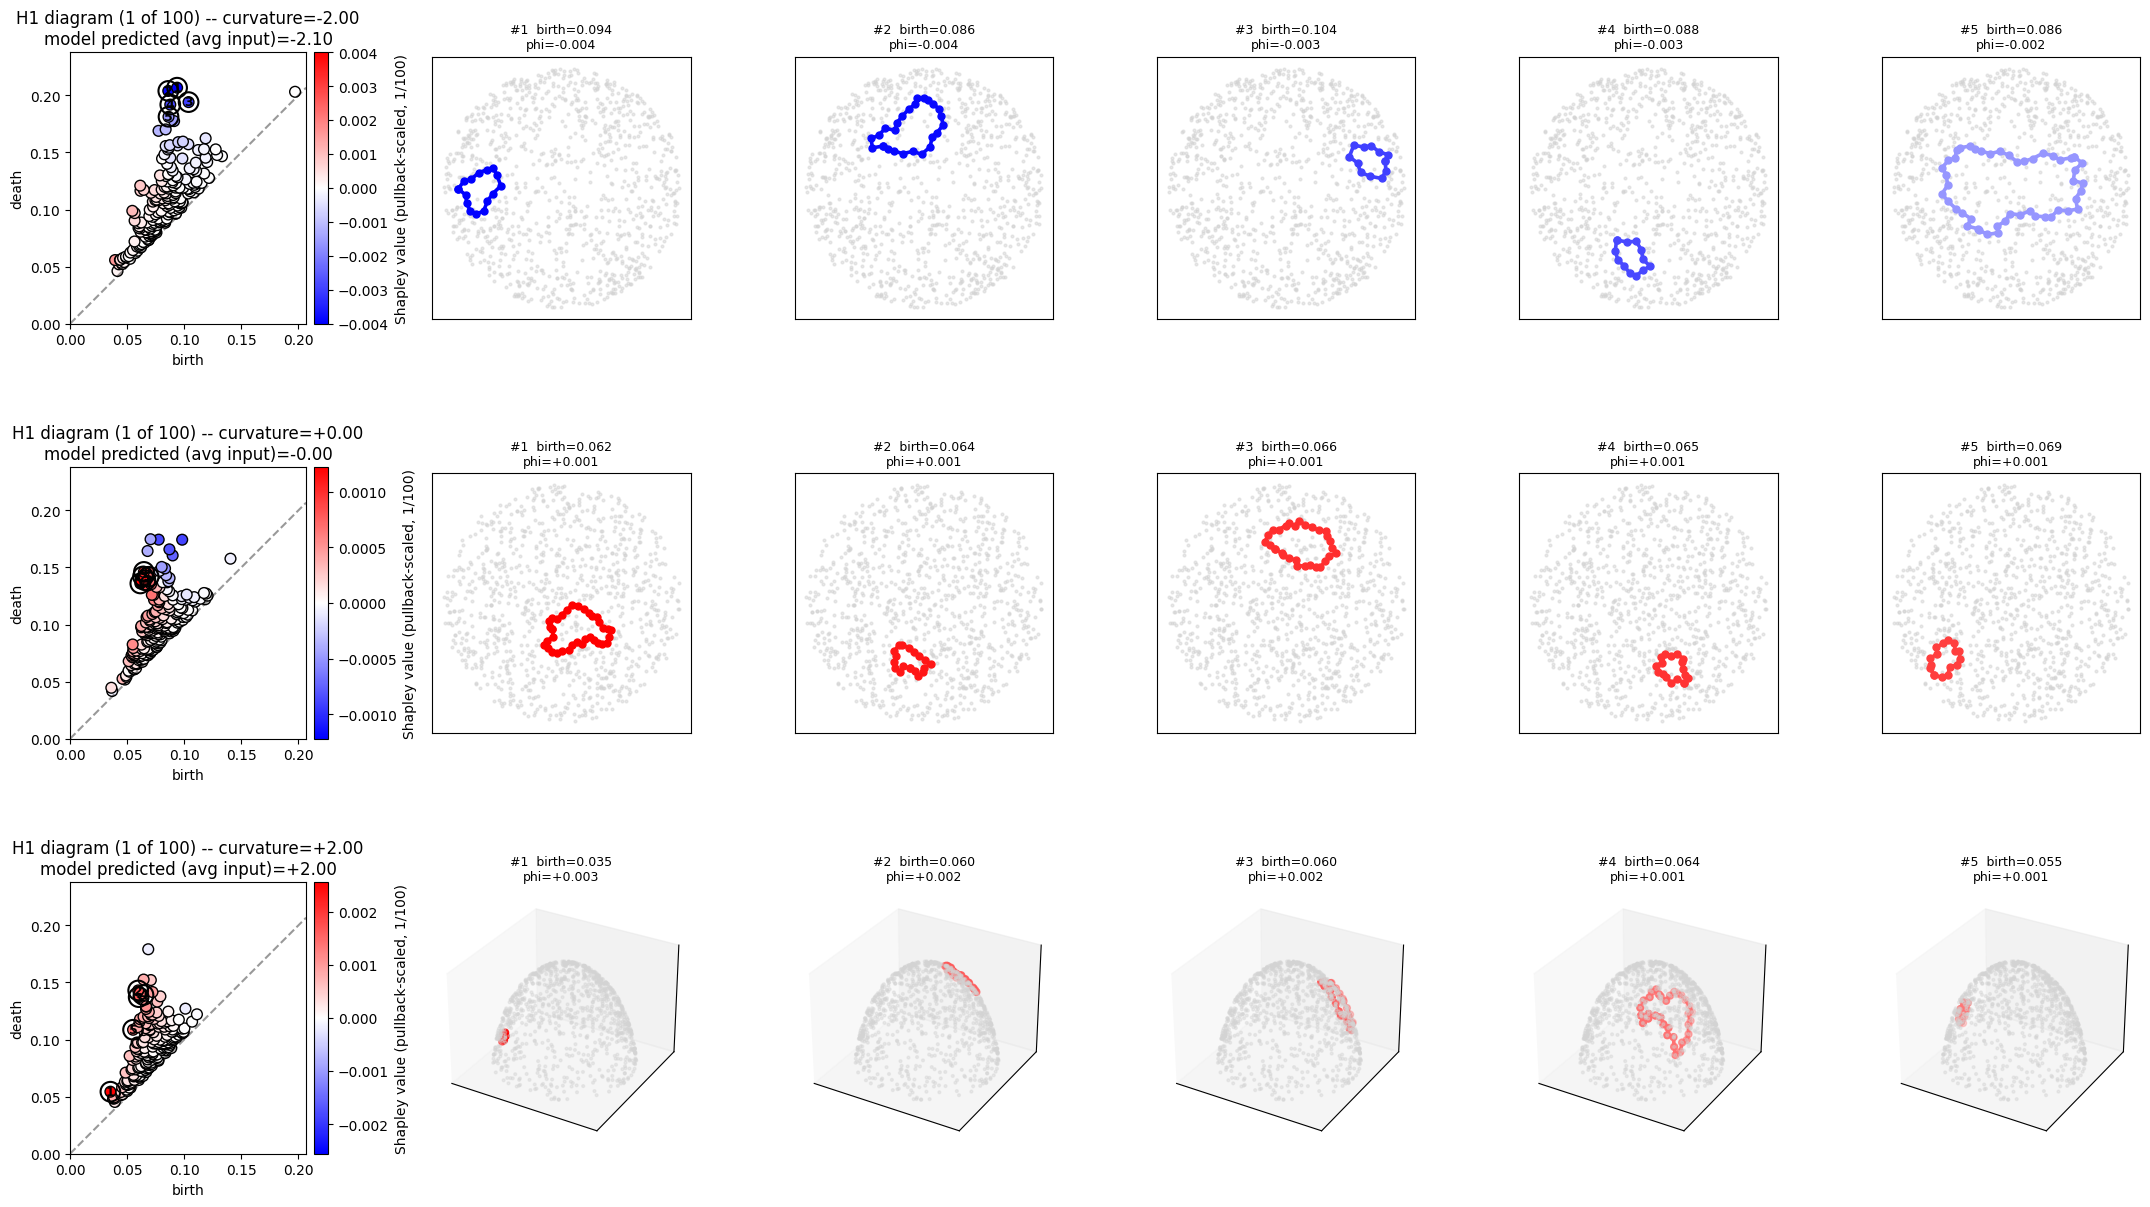

In [14]:
w_land, w_full = rescaled_weights(model, scaler, K, M)
plot_shapley_cycles(
    w_land, w_full,
    predict_fn=lambda row: float(model.predict(scaler.transform(row.reshape(1, -1)))[0]),
    value_name="model predicted",
    svg_filename="curvature_shap_representative_cycles.svg",
)


## 7. Explaining PC1 itself, the same way

Section 4's PCA sanity check found that PC1 tracks curvature almost perfectly (Section 4's
correlation/explained-variance numbers). Since PC1 is a linear function of the landscape --
$\mathrm{PC1}(x) = \langle v_1,\, x - \bar x\rangle = \langle v_1, x\rangle - \text{const}$
for the first component's loading vector $v_1$ -- it has exactly the $f(x)=\langle w,x\rangle+b$
form Theorem 1 needs, with $w=v_1$. So PC1 can be explained with the *exact same* closed-form
machinery as the regressor, no new derivation and no new code beyond a different weight
vector (`pca_weights` in Section 5) and a different `predict_fn` -- `plot_shapley_cycles` from
Section 6 is reused verbatim.

This explains a different (if closely related) quantity than Section 6: not "why did the
model predict this curvature," but "why does this diagram's landscape land where it does
along the leading axis of variation in the data." Given how tightly PC1 tracks curvature here,
expect the two sections' attributions to look similar, but they are not required to agree in
general -- PC1 is defined purely from the unsupervised structure of `X`, with no reference to
the curvature labels `y` at all.


curvature=-2.00: [this diagram, pullback-scaled] sum(phi)= 0.004991  Delta= 0.004991  |diff|=8.67e-19
              [true averaged input, all 100 diagrams] PC1 score=+0.204
curvature=+0.00: [this diagram, pullback-scaled] sum(phi)= 0.002114  Delta= 0.002114  |diff|=4.34e-19
              [true averaged input, all 100 diagrams] PC1 score=-0.001
curvature=+2.00: [this diagram, pullback-scaled] sum(phi)=-0.000327  Delta=-0.000327  |diff|=5.42e-20
              [true averaged input, all 100 diagrams] PC1 score=-0.183


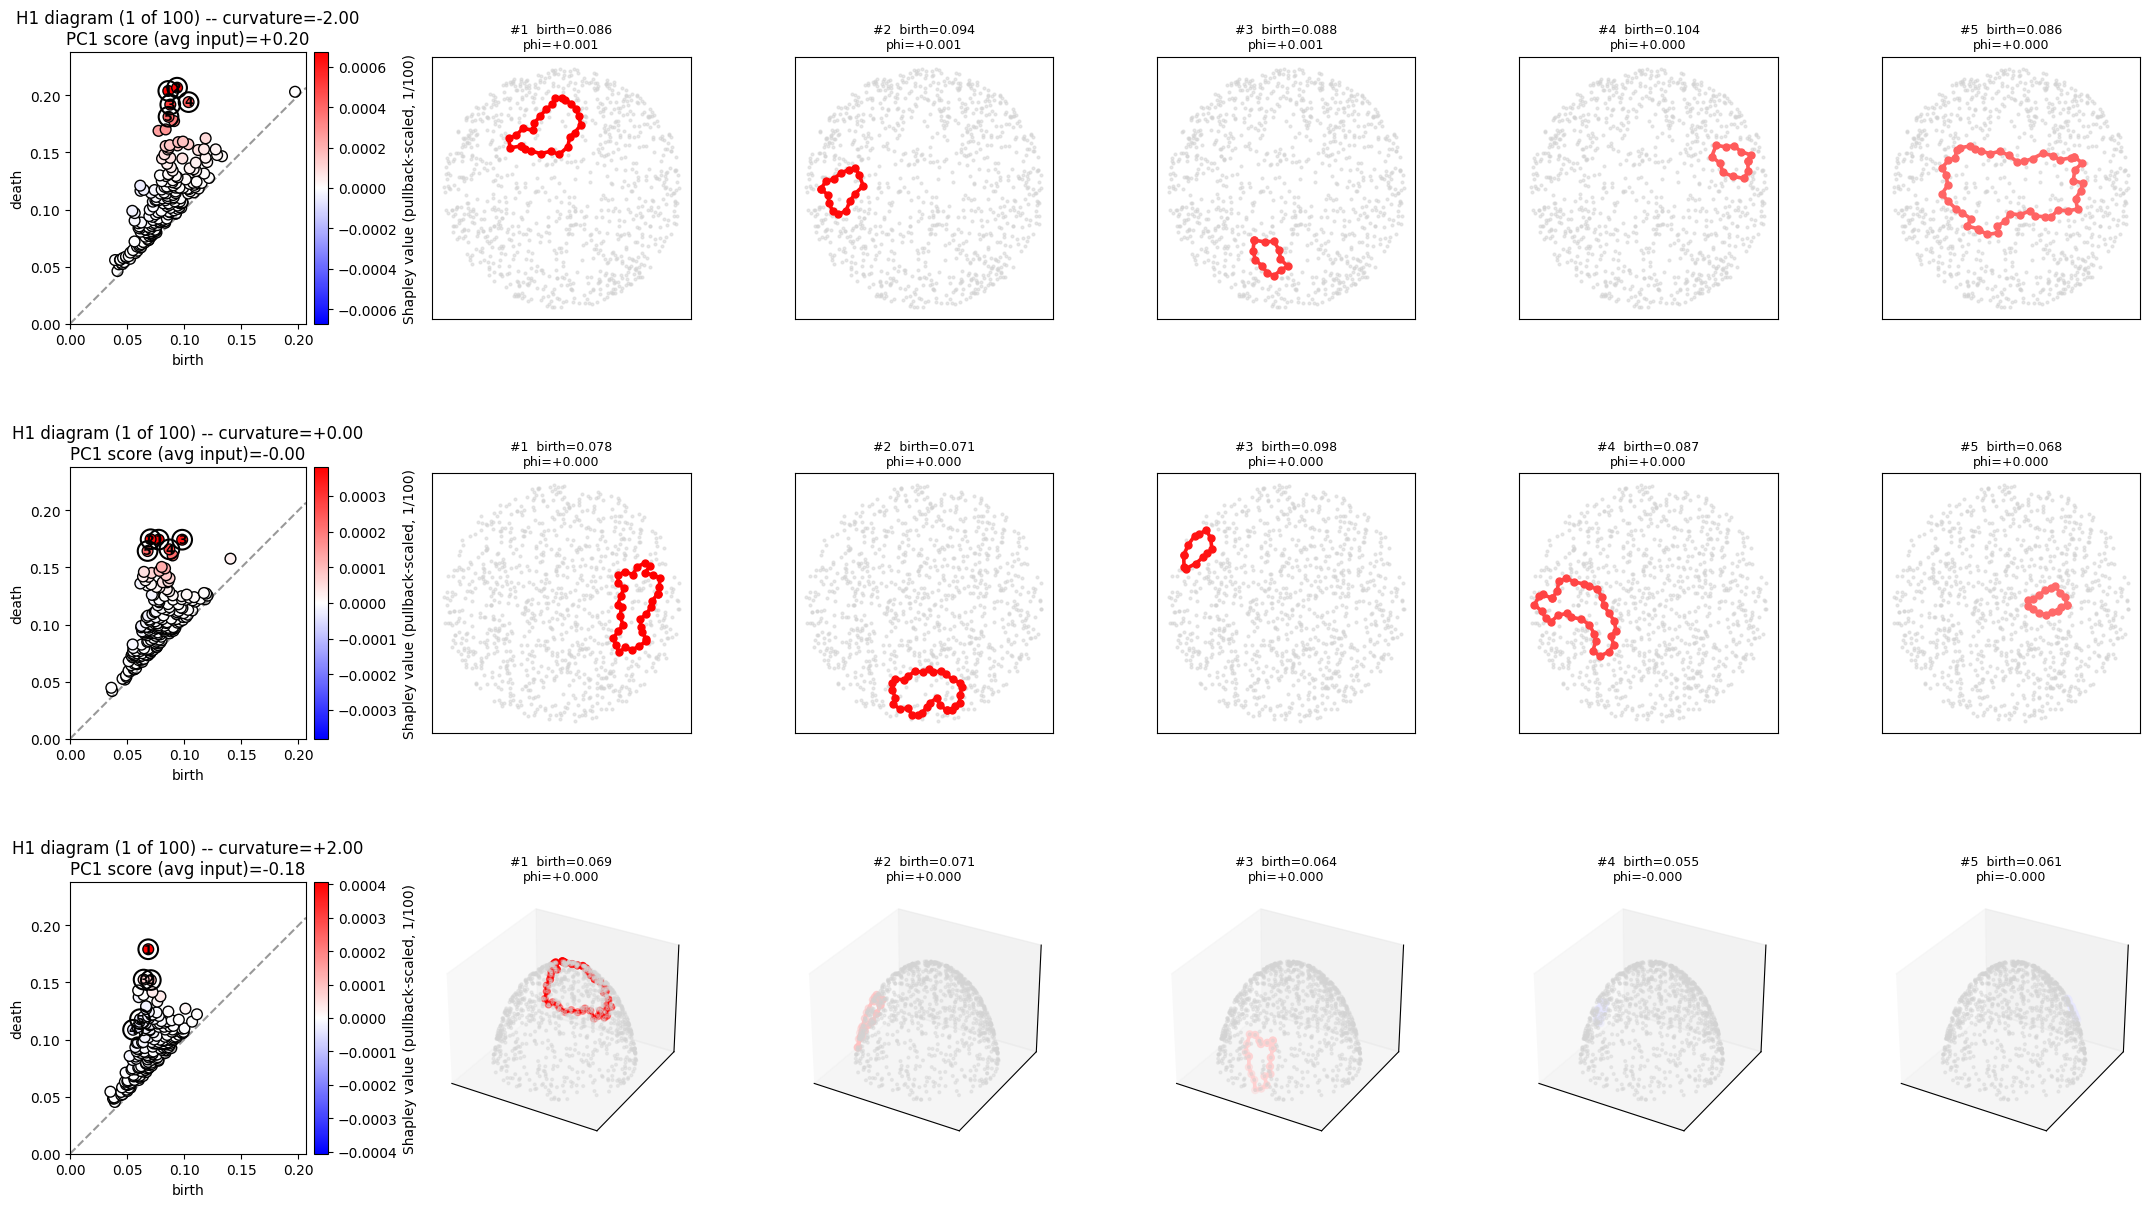

In [15]:
w_land_pca, w_full_pca = pca_weights(pca, K, M)
plot_shapley_cycles(
    w_land_pca, w_full_pca,
    predict_fn=lambda row: float(pca.transform(row.reshape(1, -1))[0, 0]),
    value_name="PC1 score",
    svg_filename="curvature_pca_shap_representative_cycles.svg",
)


## Notes on design choices / caveats

- **Scale and runtime.** 101 curvatures x 100 repeats x 1000 points = 10,100 Rips H1
  computations, as requested. `ripser` (purpose-built for exactly this) plus a data-driven
  `max_edge_length` are the mitigations; the pilot cell in Section 3 gives a real, measured
  runtime estimate before the full sweep runs. If it's too slow on your hardware, reduce
  `N_REPEATS` and/or coarsen the curvature step (`np.linspace(-2, 2, 101)` -> fewer points) --
  both are single-line changes.
- **Ambient dimension mismatch.** `DIM=2` gives 2D points for `c<=0` and 3D points (on the
  embedded sphere) for `c>0`. This is inherent to how a positively-curved space embeds, not
  something to "fix" -- the notebook's plotting code handles both cases.
- **Bug fixes and a performance rewrite to the sampling code.** See Section 1's markdown:
  `sample_sph2`'s array shape and loop bound, a mean-1-instead-of-mean-0 noise bias (inert
  here since `noise=0.0`), and vectorizing the three `*_distance` functions, which were
  originally a double Python loop -- at N=1000 that alone could plausibly take hours across
  10,100 clouds, independent of GUDHI.
- **Two H1 backends, deliberately.** `ripser` for the 10,097 non-example clouds (fast, values
  only); GUDHI for the 3 examples (slower, but exposes the birth edge needed for cycle
  reconstruction). Neither could be benchmarked against a real install while writing this (no
  network access in the authoring sandbox), so the pilot cell's measured timing is the actual
  source of truth for how fast `ripser` is on your hardware, not anything claimed here.
- **No background triangulation in the cycle plots.** A deliberate departure from the
  alpha-complex notebooks: a Rips graph at N=1000 is far too dense to draw usefully.
- **Regression target, not classification.** `rescaled_weights` no longer takes a class label;
  `LinearSVR.coef_` is a single vector.
- **Trained on averaged landscapes (101 rows), not all 10,100.** Matches Bubenik et al.'s own
  reported design; see Section 4's markdown for the small-training-set caveat and why
  averaging over 100 repeats is a real noise reduction, not just fewer rows. The 1D PCA cell
  right after training is an independent check that this reproduces their reported near-perfect
  diagonal fit.
- **Shapley values in Section 6 are pullback-scaled by `1/N_REPEATS`.** Each plotted diagram is
  one representative out of the 100 averaged into its curvature's training row; its Shapley
  values are its own closed-form values divided by 100, reflecting its actual share of the
  trained model's use of that average -- not what its Shapley values would be if it alone were
  the model's input. This is an exact identity for a linear model (see the chat derivation:
  averaging is linear, so no cross-diagram terms appear), not an approximation.
- **Representative cycle.** Same BFS-based (fewest-hops, not minimal-weight) construction as
  the other notebooks -- see their notes for the same non-minimality caveat.
- **Section 7 explains PC1, not just the regressor.** `pca.transform(x)[0]` is itself linear in
  the landscape (`<v_1, x> - const`), so `plot_shapley_cycles` from Section 6 is reused as-is
  with `w = pca.components_[0]` in place of the rescaled SVR weights. This explains the leading
  unsupervised axis of variation in the averaged landscapes, a quantity that is closely related
  to -- but conceptually distinct from -- the supervised curvature prediction; the two happen
  to nearly agree here because PC1 tracks curvature so tightly.
